# Improved liver-tumour synthesis: training, size control and insertion

This notebook demonstrates the two modules added next to `Syn_Img_Pipeline_fixed.py`:

* **`syn_training_improved.py`**: training and generation improvements ported from the reference `synthesis.py`.
* **`insertion_improved.py`**: host insertion improvements ported from the reference `insertion.py`.

Neither module changes `Syn_Img_Pipeline_fixed.py`. Both import it and reuse its data preparation, networks, mask head, blending and
file formats. A checkpoint written by the improved trainer still loads with `MultiGAN.load`, and `samples.npz` still reads with
`run_insert` and `evaluate_synthesis.py`.

Everything below runs on **synthetic stand-in data** on a CPU in a few minutes, so it works without LiTS. Section 6 shows the
commands for real data. Toy numbers show that the code paths work. They are not evidence of realism or of a segmentation benefit.

## What was compared

| Aspect | `Syn_Img_Pipeline_fixed.py` (current) | Reference `synthesis.py` / `insertion.py` | Taken over here |
|---|---|---|---|
| Discriminator overfitting on a few hundred patches | nothing | DiffAugment on real and fake D inputs | yes, `diffaug` (flips, in-plane rot90, brightness/contrast/noise) |
| Sampling weights | live generator weights | EMA of the generation path (PGGAN) | yes, `Ema`; checkpoint `modules` = averaged weights |
| WGAN-GP critic drift | none | drift term 1e-3 * E[C(real)^2] | yes |
| Model selection | last epoch | per-epoch HU quality score + early stopping | yes, `quality_score`, `gan_best.pt`, `early_stop_decision` |
| Tumour size | whatever the GAN produces | radius-conditioned generators (small/medium/large) | size control by accept-until-target per class (the multi-GAN stays unconditional) |
| Insertion site | eroded liver, away from tumours | vessel-aware candidate map + real-shape clearance check | yes, `segment_vessels`, `HostMaps`, `candidate_centres` |
| Physical size at insertion | unchanged | patch rescaled to the requested radius in mm | yes, `prepare_patch` (5 / 10 / 15 mm or any value) |
| HU harmonisation | patch ring mean onto host liver mean | robust shell 3-10 mm, vessels excluded | yes, plus an air-free generated ring and alpha 0 on vessels |
| Mass effect | none | local scaling warp, Jacobian-validated | yes, `mass_effect` (I = 0 / 20 / 30) |
| Capsule | none | phase-dependent ring | yes, optional (`capsule=True`) |
| Quality control | mask gate only | 15 automatic checks, reject or flag | 9 per-insertion checks, edit box restored on reject, `qc_report.csv` |

Not taken over: the reference's conditional 5-network training (radius-conditioned DCGAN/WGAN generators with a geometry prior,
segmenter-consistency losses, a style-transfer net). That is a different architecture and would replace the current pipeline rather
than improve it.

In [1]:
import os, sys, json, time, logging
import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd

# notebook location: "Image Synthesis/"; demo outputs go to results/ (git-ignored)
HERE = os.path.abspath(".") if os.path.exists("Syn_Img_Pipeline_fixed.py") else os.path.abspath("Image Synthesis")
ROOT = os.path.dirname(HERE)
DEMO = os.environ.get("LITS_DEMO_DIR", os.path.join(ROOT, "results", "improved_synthesis_demo"))
os.environ["LITS_GAN_RESULTS_DIR"] = DEMO  # read by the pipeline at import time
sys.path.insert(0, HERE)
import syn_training_improved as T
import insertion_improved as I
S = T.S
%matplotlib inline
# (the pipeline selects the Agg backend at import; switch back so figures render here)
os.makedirs(DEMO, exist_ok=True)
S.setup_logging(DEMO)
S.set_seed(0)
DEV = torch.device("cpu")
print("pipeline module:", S.__file__)
print("demo outputs   :", DEMO)

2026-11-02 21:01:43,789 - INFO - seeds: random=0 numpy=0 torch=0


pipeline module: C:\Users\shrey\Downloads\Liver-Tumor-Segmentation-GitHub\Liver-Tumor-Segmentation-GitHub\Image Synthesis\Syn_Img_Pipeline_fixed.py
demo outputs   : C:\Users\shrey\Downloads\Liver-Tumor-Segmentation-GitHub\Liver-Tumor-Segmentation-GitHub\results\improved_synthesis_demo


## 1. A toy patch set in the pipeline's `patches.npz` format

Lobulated tumours (35-70 HU) in textured liver (100-120 HU) with random radii, 32³ patches at 1 mm. The real `prepare` stage produces
the same file layout (64³, `images` in [-1, 1] as float16, `masks`, `healthy`, `meta`, `healthy_cid`, `work_mm`, `ids`).

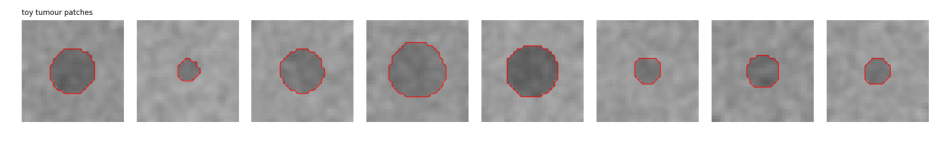

In [2]:
P, N_T, N_H = 32, 48, 12
rng = np.random.default_rng(0)
imgs, masks, meta = [], [], []
for i in range(N_T):
    x, m = I.toy_patch(P, radius_mm=float(rng.uniform(3.5, 9.0)), seed=i, tumour_hu=float(rng.uniform(35, 70)),
                       liver_hu=float(rng.uniform(100, 120)))
    imgs.append(x); masks.append(m); meta.append((i // 6, 1))  # 8 pseudo volumes
healthy = [S.to_unit((110 + 8 * rng.standard_normal((P, P, P))).astype(np.float32)) for _ in range(N_H)]
patches_path = os.path.join(DEMO, "patches.npz")
S.save_npz_atomic(patches_path, images=np.stack(imgs).astype(np.float16), masks=np.stack(masks).astype(np.uint8),
                  healthy=np.stack(healthy).astype(np.float16), meta=np.array(meta), healthy_cid=np.arange(N_H) % 8,
                  work_mm=np.float32(1.0), ids=np.arange(8))
S.save_montage(os.path.join(DEMO, "toy_patches.png"), [("toy tumour patches", np.stack(imgs)[:8], np.stack(masks)[:8])])
plt.figure(figsize=(12, 2.4)); plt.imshow(plt.imread(os.path.join(DEMO, "toy_patches.png"))); plt.axis("off"); plt.show()

## 2. Training improvements

### 2a. Differentiable augmentation

Every discriminator / critic input (real and fake, in the D and the G step) is augmented. The augmentation is differentiable, so the
generator is trained through it. The z axis (the slice axis of the source CT) is never rotated into the plane.

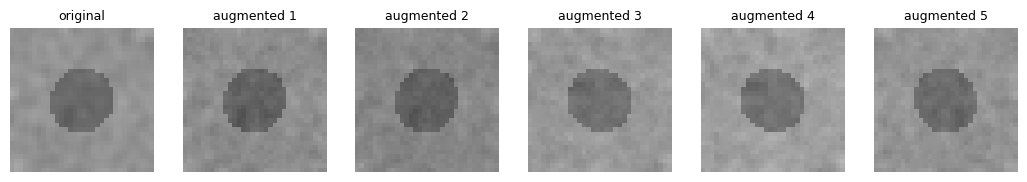

In [3]:
x = torch.from_numpy(np.stack(imgs[:1]).astype(np.float32))[:, None]
torch.manual_seed(1)
import random; random.seed(1)
views = [x] + [T.diffaug(x, p=0.9) for _ in range(5)]
fig, axs = plt.subplots(1, 6, figsize=(13, 2.4))
for ax, v, t in zip(axs, views, ["original"] + [f"augmented {k}" for k in range(1, 6)]):
    ax.imshow(v[0, 0, :, :, P // 2].T, cmap="gray", vmin=-1, vmax=1, origin="lower"); ax.set_title(t, fontsize=9); ax.axis("off")
plt.show()

### 2b. The quality score behaves as intended

The per-epoch score compares generated with real held-out tumour patches:
W1(tumour-voxel HU) + |contrast gap| + `sharp_weight` × |sharpness gap|, in HU, lower is better. A sanity check on real data: a second
set of real patches should score near 0, while blurred or brightened tumours should score higher. The sharpness term catches blur
that intensity statistics alone would miss.

In [4]:
from scipy import ndimage as ndi
from scipy.stats import wasserstein_distance
A, B = np.stack(imgs[:24]), np.stack(imgs[24:])
mA, mB = np.stack(masks[:24]), np.stack(masks[24:])
ref = T.quality_reference(A, mA)

def score(p, m):  # the formula of T.quality_score, applied to given patches instead of generated ones
    g = T.tumour_statistics(p, m)
    w1 = wasserstein_distance(g["vox"], ref["vox"]); ce = abs(g["contrast"].mean() - ref["contrast"].mean())
    se = abs(g["sharp"].mean() - ref["sharp"].mean())
    return dict(score=w1 + ce + T.SHARP_WEIGHT * se, hu_w1=w1, contrast_err=ce, sharp_err=se)

blur = np.stack([ndi.gaussian_filter(b, 1.2) for b in B])
bright = np.stack([np.where(m, np.clip(b + 0.15, -1, 1), b) for b, m in zip(B, mB)])  # +0.15 on [-1,1] = +26 HU
pd.DataFrame({"real B (other patches)": score(B, mB), "blurred real B": score(blur, mB), "tumour +26 HU": score(bright, mB)}).T.round(2)

,score,hu_w1,contrast_err,sharp_err
real B (other patches),6.53,4.73,1.76,0.04
blurred real B,32.12,15.45,13.88,2.79
tumour +26 HU,59.20,30.98,28.01,0.21


### 2c. Train the improved multi-GAN (toy run)

`train_improved` is `S.train` with `ImprovedMultiGAN`, a quality score after every epoch, `checkpoints/gan_best.pt` and optional
early stopping. Width 8 and 32³ keep this to about a minute on a CPU. The toy set is easy, so the mask head and the score move within a
few epochs. Real LiTS patches need 50+ epochs at width 32 (the defaults), and the score is only computed on samples that pass the mask
gate (`gate_accept`).

2026-11-02 21:01:47,681 - INFO - [improved] device cpu; 48 tumour / 12 healthy patches 32^3 at 1.0 mm; batch 4; epochs 8; diffaug p=0.5 ema=0.999 drift=0.001; quality reference 12 real patches (held-out volumes); early stopping off


2026-11-02 21:01:53,368 - INFO - epoch 1/8 (6s) d1=1.117 g1=0.902 d2=1.213 g2=0.826 w_critic=0.028 w_gp=0.490 w_drift=0.000 ag_d=1.185 ag_g=0.825 ag_l1=0.067 mask=1.244 w_g=-0.061 | quality 88.5 HU (gate 1.00), best epoch 1


2026-11-02 21:01:59,383 - INFO - epoch 2/8 (12s) d1=0.759 g1=1.436 d2=0.853 g2=1.235 w_critic=-0.732 w_gp=0.518 w_drift=0.001 ag_d=0.795 ag_g=1.332 ag_l1=0.022 mask=0.818 w_g=0.197 | quality 77.3 HU (gate 1.00), best epoch 2


2026-11-02 21:02:05,204 - INFO - epoch 3/8 (18s) d1=0.575 g1=1.902 d2=0.697 g2=1.485 w_critic=-1.310 w_gp=0.707 w_drift=0.002 w_g=0.381 ag_d=0.598 ag_g=1.817 ag_l1=0.012 mask=0.739 | quality 74.5 HU (gate 1.00), best epoch 3


2026-11-02 21:02:10,978 - INFO - epoch 4/8 (23s) d1=0.566 g1=2.181 d2=0.634 g2=2.035 w_critic=-1.601 w_gp=0.851 w_drift=0.003 ag_d=0.536 ag_g=2.173 ag_l1=0.020 mask=0.705 w_g=0.901 | quality 69.8 HU (gate 1.00), best epoch 4


2026-11-02 21:02:17,311 - INFO - epoch 5/8 (30s) d1=0.737 g1=2.178 d2=0.526 g2=2.279 w_critic=-1.867 w_gp=0.905 w_drift=0.003 ag_d=0.859 ag_g=1.921 ag_l1=0.081 mask=0.650 w_g=0.984 | quality 62.4 HU (gate 1.00), best epoch 5


... (2 outputs left out)

2026-11-02 21:02:34,854 - INFO - epoch 8/8 (47s) d1=0.772 g1=2.297 d2=0.748 g2=2.116 w_critic=-2.845 w_gp=0.975 w_drift=0.005 w_g=1.553 ag_d=0.505 ag_g=2.088 ag_l1=0.083 mask=0.363 | quality 33.8 HU (gate 1.00), best epoch 7


2026-11-02 21:02:35,215 - INFO - mask head train: dice=0.793 healthy_fp_vox_frac=0.000 healthy_fp_patches=0.000


2026-11-02 21:02:35,216 - INFO - mask head heldout: dice=0.774 healthy_fp_vox_frac=0.000 healthy_fp_patches=0.000


trained in 51 s; checkpoints: ['gan_best.pt', 'gan_last.pt']


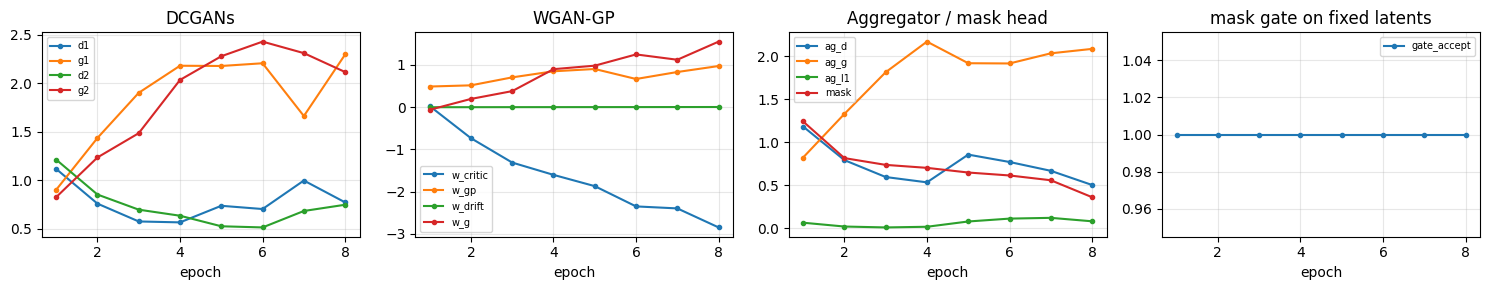

,score,hu_w1,contrast_err,sharp_err,gate_accept
epoch,,,,,
1,88.488064,31.126288,53.820312,3.541464,1.0
2,77.314907,23.198954,52.860943,1.255011,1.0
3,74.502077,20.224024,49.310380,4.967673,1.0
4,69.817429,19.834029,44.147728,5.835672,1.0
5,62.397710,24.285586,32.397036,5.715088,1.0
6,41.202566,19.691649,15.899366,5.611551,1.0
7,32.346519,22.024745,5.235328,5.086447,1.0
8,33.840801,22.994648,6.383312,4.462841,1.0


In [5]:
t0 = time.time()
model = T.train_improved(patches_path, epochs=8, device=DEV, results_dir=DEMO, width=8, quality_n=8, sample_every=8, resume=False,
                         patience=0)
print(f"trained in {time.time() - t0:.0f} s; checkpoints: {sorted(os.listdir(os.path.join(DEMO, 'checkpoints')))}")
m = S.read_json(os.path.join(DEMO, "train_metrics.json"))
h = pd.DataFrame(m["loss_history"]).set_index("epoch")
q = pd.DataFrame(m["quality_history"]).set_index("epoch")
fig, axs = plt.subplots(1, 4, figsize=(15, 3))
for ax, (title, keys) in zip(axs, [("DCGANs", ["d1", "g1", "d2", "g2"]), ("WGAN-GP", ["w_critic", "w_gp", "w_drift", "w_g"]),
                                   ("Aggregator / mask head", ["ag_d", "ag_g", "ag_l1", "mask"]), ("mask gate on fixed latents", ["gate_accept"])]):
    for k in keys:
        src = q if k in q else h
        if k in src:
            ax.plot(src.index, src[k], marker="o", ms=3, label=k)
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend(fontsize=7); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
q[["score", "hu_w1", "contrast_err", "sharp_err", "gate_accept"]]

In [6]:
# the improved checkpoint is backward compatible: the original class loads it (its "modules" are the EMA weights)
legacy = S.MultiGAN.load(os.path.join(DEMO, "checkpoints", "gan_last.pt"), DEV)
print("S.MultiGAN.load ok:", type(legacy).__name__)
print("early_stop_decision([5, 4, 4.5, 4.2, 4.1], patience=3, min_epochs=3, min_delta=0) ->", T.early_stop_decision([5, 4, 4.5, 4.2, 4.1], 3, 3, 0.0))

S.MultiGAN.load ok: MultiGAN
early_stop_decision([5, 4, 4.5, 4.2, 4.1], patience=3, min_epochs=3, min_delta=0) -> (2, True)


### 2d. Size-controlled generation

The multi-GAN is unconditional, so size is controlled after the fact. Every candidate is labelled by the mask head, cleaned, measured
(equivalent spherical radius) and kept only if its class (small ≤ 6 mm, medium ≤ 14 mm, large ≤ 28 mm) still needs samples. The radius
histogram in `stats` shows which sizes the generator actually produces: the toy GAN mostly produces medium tumours, so `small` stays
empty. If nothing passes the gate (an untrained model), the cell falls back to procedural stand-in patches, which the insertion code
treats exactly like generated ones.

In [7]:
st = {}
by_size = T.generate_by_size(model, n_per_class=4, classes=("small", "medium"), work_mm=1.0, max_attempts=64, stats=st)
print(json.dumps({k: st[k] for k in ("tried", "accepted", "rejects")}))
if sum(len(v[0]) for v in by_size.values()) == 0:
    print("toy model: nothing passed the mask gate -> using procedural stand-ins for the insertion demo")
    by_size = {}
    for c, rr in (("small", (4.0, 5.5)), ("medium", (8.0, 12.0)), ("large", (14.5, 17.0))):
        ps, ms = zip(*[I.toy_patch(64, float(r), seed=10 + j) for j, r in enumerate(np.linspace(*rr, 3))])
        by_size[c] = (np.stack(ps), np.stack(ms).astype(np.uint8), np.array([I.equivalent_radius_mm(x, (1, 1, 1)) for x in ms], np.float32))
samples_path = T.save_samples(os.path.join(DEMO, "synthetic", "samples.npz"), by_size, work_mm=1.0)
d = S.load_npz(samples_path)
print({k: v.shape for k, v in d.items()}, "classes:", sorted(set(d["size_class"])), "radii (mm):", np.round(d["radius_mm"], 1))

2026-11-02 21:02:37,467 - INFO - size-controlled generation (aggregator): {'small': 0, 'medium': 4} in 64 attempts; rejects {'medium_full': 60}


{"tried": 64, "accepted": {"small": 0, "medium": 4}, "rejects": {"medium_full": 60}}
{'patches': (4, 32, 32, 32), 'masks': (4, 32, 32, 32), 'radius_mm': (4,), 'size_class': (4,), 'work_mm': ()} classes: [np.str_('medium')] radii (mm): [7.3 6.9 7.5 7.4]


## 3. Insertion improvements on a synthetic host

The toy host has anisotropic 0.8 × 0.8 × 2.5 mm voxels (like many LiTS volumes), an ellipsoidal liver, four bright vessels and one
existing tumour.

### 3a. Vessel mask and vessel-aware candidate map

parenchyma 110.2 HU -> vessel threshold 125.2 HU; vessel volume 11.1 ml (2.1% of liver); Dice vs the true toy vessels 0.69


candidate voxels left after each criterion: {'depth': 135411, 'vessel': 65949, 'tumour_gap': 56791, 'window': 46946}


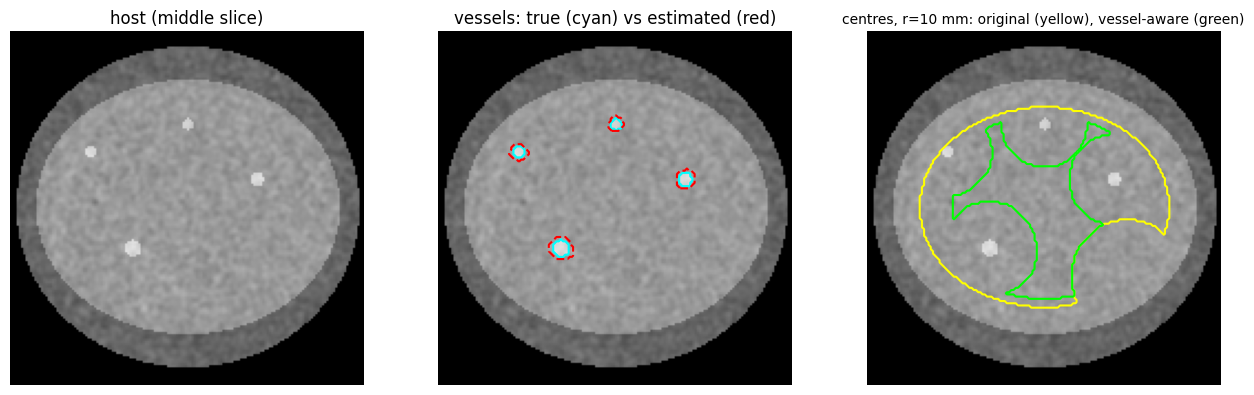

In [8]:
hu, seg, sp, ves_true = I.toy_host(seed=0)
ves, vst = I.segment_vessels(hu, seg, sp)
dice = 2 * (ves & ves_true).sum() / (ves.sum() + ves_true.sum())
print(f"parenchyma {vst['parenchyma_mean_hu']:.1f} HU -> vessel threshold {vst['threshold_hu']:.1f} HU; vessel volume {vst['volume_ml']:.1f} ml "
      f"({100 * vst['fraction_of_liver']:.1f}% of liver); Dice vs the true toy vessels {dice:.2f}")
p = I.InsertParams(target_radius_mm=10.0)
maps = I.HostMaps(seg, ves, sp)
img, msk = I.toy_patch(64, 10.0, seed=3)
patch_rs, m_rs, scale = I.prepare_patch(img, msk, sp, 1.0, 10.0, p)
r_eq = I.equivalent_radius_mm(m_rs, sp)
cen = np.rint(np.argwhere(m_rs).mean(0)).astype(int)
cands, counts = I.candidate_centres(maps, r_eq, cen, m_rs.shape, seg.shape, p)
print("candidate voxels left after each criterion:", counts)
z = seg.shape[2] // 2
cand_map = np.zeros(seg.shape, bool); cand_map[tuple(cands.T)] = True
naive = np.zeros(seg.shape, bool)  # what the original rule allows: eroded liver, away from tumours, vessels ignored
naive[tuple((np.argwhere((maps.depth > r_eq) & (maps.tdist > r_eq + p.exclude_mm)) + maps.origin).T)] = True
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
axs[0].imshow(hu[:, :, z].T, cmap="gray", vmin=-100, vmax=250, origin="lower"); axs[0].set_title("host (middle slice)")
axs[1].imshow(hu[:, :, z].T, cmap="gray", vmin=-100, vmax=250, origin="lower")
axs[1].contour(ves_true[:, :, z].T, [0.5], colors="cyan"); axs[1].contour(ves[:, :, z].T, [0.5], colors="red", linestyles="--")
axs[1].set_title("vessels: true (cyan) vs estimated (red)")
axs[2].imshow(hu[:, :, z].T, cmap="gray", vmin=-100, vmax=250, origin="lower")
axs[2].contour(naive[:, :, z].T, [0.5], colors="yellow"); axs[2].contour(cand_map[:, :, z].T, [0.5], colors="lime")
axs[2].set_title("centres, r=10 mm: original (yellow), vessel-aware (green)", fontsize=10)
for a in axs: a.axis("off")
plt.tight_layout(); plt.show()

### 3b. Small / medium / large insertions with mass effect and QC

The requested radius is enforced in mm: 5 / 10 / 15 mm with mass-effect intensity 0 / 20 / 30. QC compares the final tumour with the
request, including the expansion that the warp causes. The difference column shows what changed: the tumour plus, for medium and
large, the displaced surrounding tissue.

2026-11-02 21:02:38,975 - INFO - insertion: accepted; r 5.0 mm, mass effect I=0


2026-11-02 21:02:39,271 - INFO - insertion: accepted; r 10.0 mm, mass effect I=20


2026-11-02 21:02:39,791 - INFO - insertion: accepted; r 14.8 mm, mass effect I=30


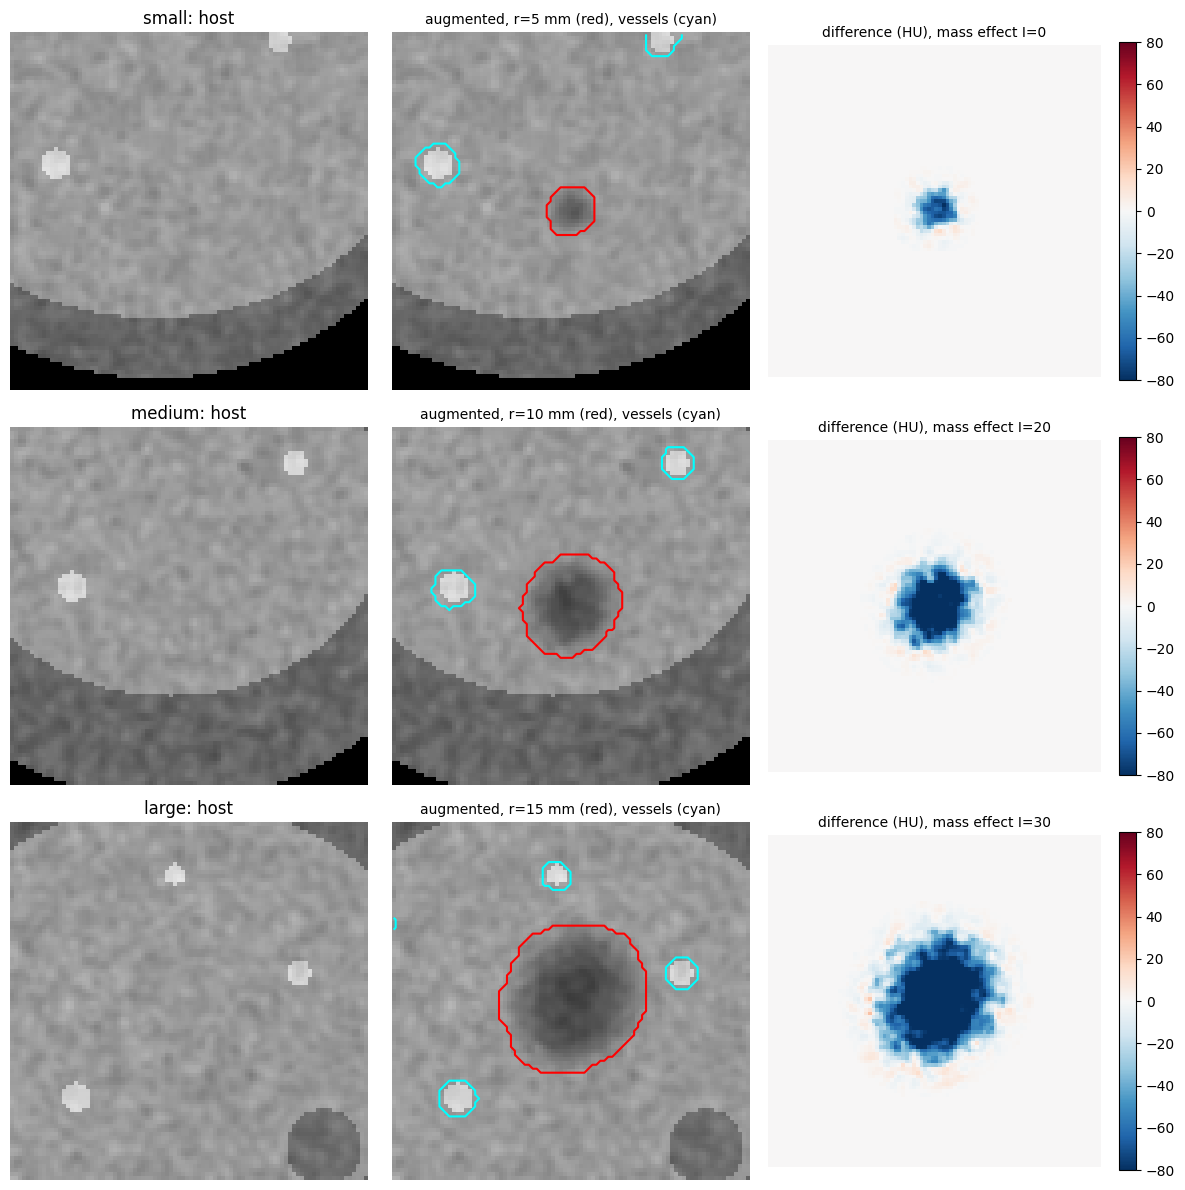

,size,accepted,reason,scale,radius_requested_mm,radius_expected_mm,radius_actual_mm,vessel_clearance_mm,liver_clearance_mm,mass_intensity,jacobian_min,max_displacement_mm,shift_hu,contrast_hu,n_label
0,small,True,,0.67,5.0,5.00,5.00,19.40,16.37,0.0,1.00,0.00,-2.64,-37.09,327
1,medium,True,,1.35,10.0,10.10,10.09,9.63,4.06,20.0,0.60,0.39,-4.67,-47.04,2689
2,large,True,,2.00,15.0,15.22,15.02,4.80,19.47,30.0,0.42,0.87,-5.51,-51.80,8870


In [9]:
samples = {"patches": d["patches"], "masks": d["masks"], "work_mm": float(d["work_mm"]), "radius_mm": d["radius_mm"]}
rows, shows = [], []
for size in ("small", "medium", "large"):
    p = I.InsertParams(target_radius_mm=I.SIZES_MM[size])
    h2, s2, v2, infos = I.insert_tumours(hu, seg, sp, samples, np.random.default_rng(7), n=1, params=p, vessels=ves)
    rows += [dict(I.qc_row(size, j, inf), size=size) for j, inf in enumerate(infos)]
    if infos[0]["accepted"]:
        shows.append((size, h2, s2, infos[0]))
fig, axs = plt.subplots(len(shows), 3, figsize=(12, 4 * len(shows)), squeeze=False)
for r, (size, h2, s2, inf) in enumerate(shows):
    c = inf["centre"]; z = int(c[2])
    xs, ys = slice(max(c[0] - 45, 0), c[0] + 45), slice(max(c[1] - 45, 0), c[1] + 45)
    axs[r][0].imshow(hu[xs, ys, z].T, cmap="gray", vmin=-100, vmax=250, origin="lower"); axs[r][0].set_title(f"{size}: host")
    axs[r][1].imshow(h2[xs, ys, z].T, cmap="gray", vmin=-100, vmax=250, origin="lower")
    axs[r][1].contour(((s2 == 2) & (seg != 2))[xs, ys, z].T, [0.5], colors="red"); axs[r][1].contour(ves[xs, ys, z].T, [0.5], colors="cyan")
    axs[r][1].set_title(f"augmented, r={inf['radius_requested_mm']:g} mm (red), vessels (cyan)", fontsize=10)
    im = axs[r][2].imshow((h2 - hu)[xs, ys, z].T, cmap="RdBu_r", vmin=-80, vmax=80, origin="lower")
    axs[r][2].set_title(f"difference (HU), mass effect I={inf['mass_effect']['intensity_applied']:g}", fontsize=10)
    plt.colorbar(im, ax=axs[r][2], fraction=.046)
    for a in axs[r]: a.axis("off")
plt.tight_layout(); plt.show()
cols = ["size", "accepted", "reason", "scale", "radius_requested_mm", "radius_expected_mm", "radius_actual_mm", "vessel_clearance_mm",
        "liver_clearance_mm", "mass_intensity", "jacobian_min", "max_displacement_mm", "shift_hu", "contrast_hu", "n_label"]
pd.DataFrame(rows)[cols].round(2)

In [10]:
# the QC checks of the large insertion, as recorded in its info dict
pd.DataFrame({k: {"passed": v["passed"], "message": v["message"]} for k, v in shows[-1][3]["qc"]["checks"].items()}).T

,passed,message
nonempty,True,8870 new tumour voxels
tumor_in_liver,True,0.00% of the tumour outside the host liver (+0...
vessel_overlap,True,0.00% in vessels
radius,True,"equivalent radius 15.02 mm, expected 15.22 mm"
contrast,True,tumour minus parenchyma -51.8 HU
texture_std,True,tumour HU std 30.9
components,True,1 connected component(s)
finite_range,True,HU finite and in range
displacement,True,warp valid


### 3c. Ablations: vessel awareness and mass effect

Twenty insertions with and without vessel awareness. The count is the number of inserted tumour voxels that land inside the **true**
toy vessels. With awareness on, the margins should keep it at zero.

In [11]:
def run(params, seed, n=20):
    over, acc = [], 0
    for k in range(n):
        h2, s2, _, infos = I.insert_tumours(hu, seg, sp, samples, np.random.default_rng(seed + k), n=1, params=params, vessels=ves)
        if infos[0]["accepted"]:
            acc += 1
            over.append(int((((s2 == 2) & (seg != 2)) & ves_true).sum()))
    return {"accepted": f"{acc}/{n}", "insertions touching vessels": int(np.sum(np.array(over) > 0)),
            "mean tumour voxels in vessels": float(np.mean(over)) if over else float("nan")}

logging.getLogger("gan_fixed").setLevel(logging.WARNING)
res = {"vessel-aware (improved)": run(I.InsertParams(target_radius_mm=10.0), 100),
       "vessels ignored (original rule)": run(I.InsertParams(target_radius_mm=10.0, vessels=False), 100)}
logging.getLogger("gan_fixed").setLevel(logging.INFO)
pd.DataFrame(res).T

,accepted,insertions touching vessels,mean tumour voxels in vessels
vessel-aware (improved),20/20,0,0.0
vessels ignored (original rule),20/20,9,48.05


2026-11-02 21:02:54,077 - INFO - insertion: accepted; r 14.8 mm, mass effect I=0


2026-11-02 21:02:54,552 - INFO - insertion: accepted; r 14.8 mm, mass effect I=30


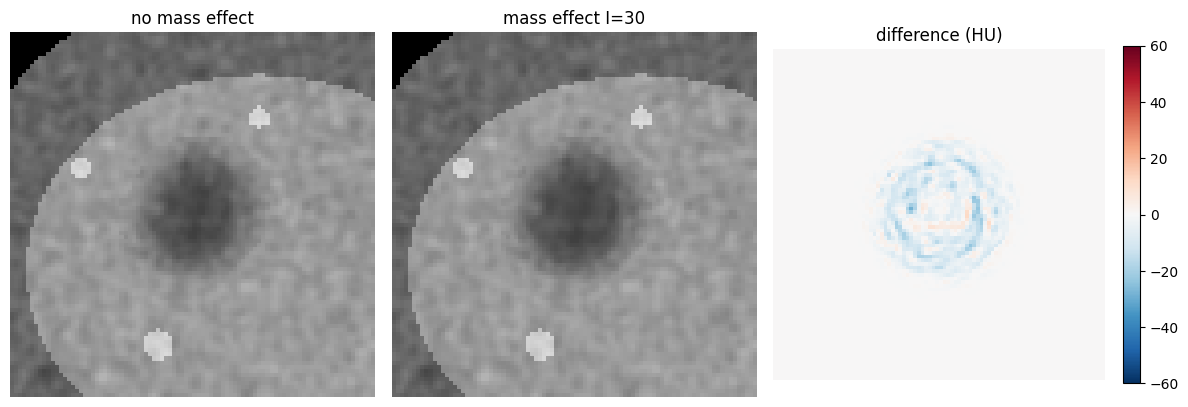

tumour radius without warp 14.82 mm, with warp 15.02 mm (expected 15.22 mm); Jacobian min 0.42


In [12]:
# mass effect on / off for the same placement (same rng seed): the warp pushes tissue outward and the tumour grows as predicted
outs = {}
for on in (False, True):
    p = I.InsertParams(target_radius_mm=15.0, mass_effect=on)
    outs[on] = I.insert_tumours(hu, seg, sp, samples, np.random.default_rng(3), n=1, params=p, vessels=ves)
(h0, s0, _, i0), (h1, s1, _, i1) = outs[False], outs[True]
c = i1[0]["centre"]; z = int(c[2]); xs, ys = slice(c[0] - 45, c[0] + 45), slice(c[1] - 45, c[1] + 45)
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
for ax, img_, t in ((axs[0], h0, "no mass effect"), (axs[1], h1, f"mass effect I={i1[0]['mass_effect']['intensity_applied']:g}")):
    ax.imshow(img_[xs, ys, z].T, cmap="gray", vmin=-100, vmax=250, origin="lower"); ax.set_title(t); ax.axis("off")
im = axs[2].imshow((h1 - h0)[xs, ys, z].T, cmap="RdBu_r", vmin=-60, vmax=60, origin="lower"); axs[2].set_title("difference (HU)"); axs[2].axis("off")
plt.colorbar(im, ax=axs[2], fraction=.046); plt.tight_layout(); plt.show()
print("tumour radius without warp", round(I.qc_row(0, 0, i0[0])["radius_actual_mm"], 2), "mm, with warp",
      round(I.qc_row(0, 0, i1[0])["radius_actual_mm"], 2), "mm (expected", round(i1[0]["radius_expected_mm"], 2),
      "mm); Jacobian min", round(i1[0]["mass_effect"]["jacobian_min"], 2))

## 4. File-based run (what `python insertion_improved.py` does)

Two toy hosts are written as `volume-<id>.nii` / `segmentation-<id>.nii`. `run_insert_improved` writes the augmented NIfTI files,
`qc_report.csv` (one row per attempted insertion, accepted or not), `insert_summary.json` and the same montage the original pipeline
produces.

2026-11-02 21:02:56,023 - INFO - insertion: accepted; r 10.0 mm, mass effect I=20


2026-11-02 21:02:56,384 - INFO - insertion: accepted; r 10.0 mm, mass effect I=20


2026-11-02 21:02:57,078 - INFO - insertion: accepted; r 10.0 mm, mass effect I=20


2026-11-02 21:02:57,438 - INFO - insertion: accepted; r 10.0 mm, mass effect I=20


2026-11-02 21:02:57,730 - INFO - improved insertion: 4/4 accepted, 2/2 hosts written -> C:\Users\shrey\Downloads\Liver-Tumor-Segmentation-GitHub\Liver-Tumor-Segmentation-GitHub\results\improved_synthesis_demo\aug_improved; reasons {}


{"hosts_written": 2, "attempts": 4, "accepted": 4, "reasons": {}}


,case,attempt,accepted,flagged,reason,sample,scale,radius_requested_mm,resampled_radius_mm,radius_expected_mm,radius_actual_mm,centre_x,centre_y,centre_z
0,1,0,True,False,NaN,3,1.349,10,10,10.1,10.09,85,81,11
1,1,1,True,False,NaN,2,1.334,10,10,10.1,10.08,74,78,25
2,2,0,True,False,NaN,1,1.457,10,10,10.1,10.09,60,98,15
3,2,1,True,False,NaN,0,1.372,10,10,10.1,10.09,77,54,28


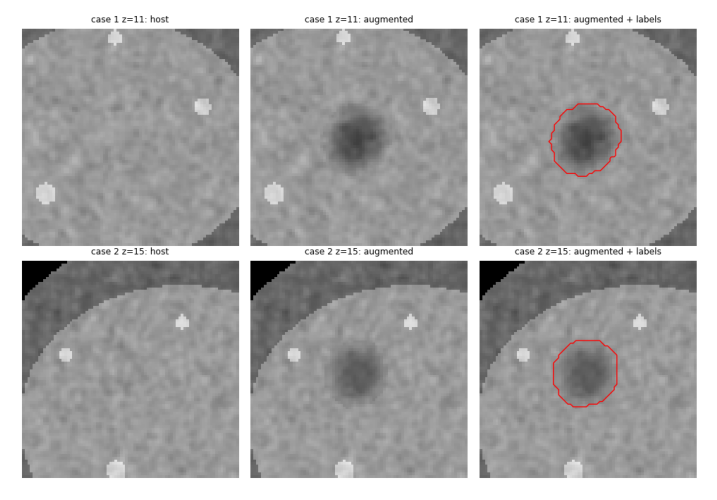

In [13]:
toy_data = os.path.join(DEMO, "toy_raw")
os.makedirs(toy_data, exist_ok=True)
for cid in (1, 2):
    h_, s_, sp_, _ = I.toy_host(seed=cid)
    aff = np.diag(list(sp_) + [1.0])
    S.save_nifti(S.to_int16(h_), aff, os.path.join(toy_data, f"volume-{cid}.nii"), np.int16)
    S.save_nifti(s_, aff, os.path.join(toy_data, f"segmentation-{cid}.nii"), np.uint8)
summary = I.run_insert_improved(samples_path, [1, 2], os.path.join(DEMO, "aug_improved"), data_dir=toy_data, n=2,
                                params=I.InsertParams(target_radius_mm=10.0), rng=np.random.default_rng(0))
print(json.dumps({k: summary[k] for k in ("hosts_written", "attempts", "accepted", "reasons")}))
display(pd.read_csv(os.path.join(DEMO, "aug_improved", "qc_report.csv")).iloc[:, :14])
plt.figure(figsize=(9, 6.5)); plt.imshow(plt.imread(os.path.join(DEMO, "aug_improved", "insertions.png"))); plt.axis("off"); plt.show()

## 5. Limits

* The multi-GAN is still unconditional. Size control is rejection sampling, so a size the generator rarely produces costs many draws.
  `generation_stats.json` records the radius histogram, so check it before relying on a class.
* The vessel mask is a threshold (the paper's approximation). On non-contrast scans it finds little. Use `vessels=False` there, or
  pass an external mask as `vessels=` to `insert_tumours`.
* The mass effect warps liver and vessel labels by nearest neighbour and tumours by a smoothed indicator. Liver boundaries within
  1.3·R of the tumour bulge slightly, by design.
* After insertion, small tumours show less contrast than the patch itself, because the blend low-passes the generated patch
  (inherited from `S.insert_one`). The `contrast` QC check catches implausible values.
* `insertion_improved.py` does not handle the cache (Colab slice-cache) source. That source keeps using
  `Syn_Img_Pipeline_fixed.run_insert_slabs`.

## 6. Real LiTS data

From the `Image Synthesis` folder, with `LITS_DATA_DIR` pointing at the raw volumes:

```bash
# prepare + improved training + size-controlled generation (gan_best.pt is used when it exists)
LITS_GAN_ES_PATIENCE=8 LITS_GAN_EPOCHS=80 python syn_training_improved.py
# vessel-aware insertion with size control, mass effect and QC into the train-part hosts
LITS_INS_SIZE=medium LITS_INS_N=2 python insertion_improved.py
# ablation folder
LITS_INS_NO_VESSELS=1 LITS_INS_OUT=$LITS_GAN_RESULTS_DIR/aug_no_vessels python insertion_improved.py
# the existing evaluator reads the improved checkpoint and samples unchanged
python evaluate_synthesis.py
```

The cell below runs the same steps from the notebook when `RUN_REAL = True` and the data exists.

In [14]:
RUN_REAL = False
RAW = os.environ.get("LITS_DATA_DIR", os.path.join(ROOT, "data", "raw"))
if RUN_REAL and os.path.exists(os.path.join(RAW, "volume-0.nii")):
    real_res = os.path.join(ROOT, "results", "gan_improved")
    ids = S.split_cases(RAW)
    S.prepare_patches(ids, os.path.join(real_res, "patches.npz"), data_dir=RAW)
    mdl = T.train_improved(os.path.join(real_res, "patches.npz"), epochs=80, results_dir=real_res, patience=8)
    best = T.ImprovedMultiGAN.load(os.path.join(real_res, "checkpoints", "gan_best.pt"), mdl.device)
    T.save_samples(os.path.join(real_res, "synthetic", "samples.npz"), T.generate_by_size(best, 16), 1.0)
    I.run_insert_improved(os.path.join(real_res, "synthetic", "samples.npz"), ids, os.path.join(real_res, "aug_improved"), data_dir=RAW,
                          params=I.InsertParams(target_radius_mm=10.0))
else:
    print("real-data run skipped (set RUN_REAL = True with LiTS volumes in", RAW, ")")

real-data run skipped (set RUN_REAL = True with LiTS volumes in C:\Users\shrey\Downloads\Liver-Tumor-Segmentation-GitHub\Liver-Tumor-Segmentation-GitHub\data\raw )
